# IMPORT THƯ VIỆN

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from __future__ import print_function, division

from keras.layers import *
from keras.models import Model, load_model
from keras.optimizers import Adam
import tensorflow as tf
tf.config.optimizer.set_experimental_options({"remapping": False})
import numpy as np
from skimage.metrics import structural_similarity as ssim
import os
import cv2
import datetime
import matplotlib.pyplot as plt
import pandas as pd
import warnings
import time
import tensorflow.keras.backend as K
import gc
from tensorflow.keras.losses import MeanSquaredError, MeanAbsoluteError
import collections

import os
import random

seed = 42

os.environ['PYTHONHASHSEED'] = str(seed)

random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

# Bắt TensorFlow chạy deterministic
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'

tf.config.experimental.enable_op_determinism()

# Tắt cảnh báo để output sạch hơn
warnings.filterwarnings("ignore")

# TIỀN XỬ LÝ DỮ LIỆU

In [ ]:
# ------------------------------
# Chuyển ảnh về ma trận ảnh Gray và resize
# ------------------------------
def matrix_images(image_folder, image_files, image_size=(224, 224)):
    matrix_img = []
    for img_file in image_files:
        img_path = os.path.join(image_folder, img_file)
        try:
            image = cv2.imread(img_path)
            if image is None:
                raise ValueError(f"Không thể đọc ảnh: {img_file}")
            image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
            # Resize ảnh
            image = cv2.resize(image, image_size)
            matrix_img.append(image)
        except Exception as e:
            print(f"Lỗi xử lý ảnh {img_file}: {e}")
    return matrix_img

In [ ]:
# ------------------------------
# Chuẩn hóa dữ liệu
# ------------------------------
def scaling_img(data_img):
    # Chuyển danh sách các mảng numpy thành một mảng numpy đa chiều
    data_array = np.array(data_img, dtype=np.float32)

    # Chuẩn hóa dữ liệu
    scaled_img = data_array / 255.0
    return scaled_img

In [ ]:
# ------------------------------
# Giảm nhiễu
# ------------------------------
def calculate_sigma(kernel_size):
    sigma = (kernel_size - 1) / 6.0
    return sigma

def reduce_noise(image, kernel_size=3):
    sigma = calculate_sigma(kernel_size)
    smoothed_image = cv2.GaussianBlur(image, (kernel_size, kernel_size), sigmaX=sigma)
    return smoothed_image

In [ ]:
# ------------------------------
# Tạo nhãn chuỗi dữ liệu các ảnh liên tiếp từ dữ liệu hình ảnh
# ------------------------------
def create_image_sequences(data, time_steps):
    num_samples, height, width, channels = data.shape
    num_frames = num_samples - time_steps
    input_sequences = np.zeros((num_frames, time_steps, height, width, channels), dtype=np.float32)
    labels = np.zeros((num_frames, height, width, channels), dtype=np.float32)

    for i in range(num_frames):
        input_sequences[i] = data[i:i+time_steps]
        labels[i] = data[i+time_steps]

    return input_sequences, labels

In [ ]:
def create_seq2img(data, time_steps_input=3, time_steps_output=6):
    N, C, H, W = data.shape
    M = N - time_steps_input - time_steps_output + 1
    if M <= 0:
        raise ValueError("Không đủ khung hình để tạo chuỗi")
    X = np.stack([data[i : i + time_steps_input] for i in range(M)])
    Y = np.stack([data[i + time_steps_input : i + time_steps_input + time_steps_output] for i in range(M)])
    return X.astype(np.float32), Y.astype(np.float32)

In [ ]:
# ------------------------------
# Chia dữ liệu
# ------------------------------
def Split_Data(X_data, y_data):
    # Chia dữ liệu thành các tập train, val, test
    size = int(len(X_data) * 0.8)
    size_val = int((len(X_data) - size) / 2)

    X_train = X_data[:size]
    X_val = X_data[size:size + size_val]
    X_test = X_data[size + size_val:]

    y_train = y_data[:size]
    y_val = y_data[size:size + size_val]
    y_test = y_data[size + size_val:]

    return X_train, y_train, X_val, y_val, X_test, y_test

# XÂY DỰNG MÔ HÌNH Radar2Radar_GAN

### Cấu trúc CBAM

In [ ]:
# Module Channel Attention: Tính toán trọng số theo kênh
class ChannelAttention(Layer):
    def __init__(self, in_channels, ratio=16, **kwargs):
        super(ChannelAttention, self).__init__(**kwargs)
        self.in_channels = in_channels
        self.ratio = ratio
        self.avg_pool = GlobalAveragePooling2D()
        self.max_pool = GlobalMaxPooling2D()
        self.shared_dense_one = Dense((in_channels // ratio), activation='relu', kernel_initializer='he_normal', use_bias=True)
        self.shared_dense_two = Dense(in_channels, kernel_initializer='he_normal', use_bias=True)

    def call(self, inputs):
        avg_pool = self.avg_pool(inputs)
        avg_pool = tf.reshape(avg_pool, [-1, 1, 1, self.in_channels])
        avg_out = self.shared_dense_two(self.shared_dense_one(avg_pool))

        max_pool = self.max_pool(inputs)
        max_pool = tf.reshape(max_pool, [-1, 1, 1, self.in_channels])
        max_out = self.shared_dense_two(self.shared_dense_one(max_pool))

        scale = tf.sigmoid(avg_out + max_out)
        return inputs * scale

    def get_config(self):
        config = super().get_config()
        config.update({ "in_channels": self.in_channels, "ratio": self.ratio})
        return config

# Module Spatial Attention: Tính toán trọng số không gian
class SpatialAttention(Layer):
    def __init__(self, kernel_size=7, **kwargs):
        super(SpatialAttention, self).__init__(**kwargs)
        self.kernel_size = kernel_size
        self.conv = Conv2D(filters=1, kernel_size=kernel_size, strides=1, padding='same',
                           activation='sigmoid', kernel_initializer='he_normal', use_bias=False)

    def call(self, inputs):
        avg_out = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_out = tf.reduce_max(inputs, axis=-1, keepdims=True)
        concat = tf.concat([avg_out, max_out], axis=-1)
        scale = self.conv(concat)
        return inputs * scale

    def get_config(self):
        config = super().get_config()
        config.update({"kernel_size": self.kernel_size})
        return config

# CBAM module kết hợp Channel Attention và Spatial Attention
class CBAM(Layer):
    def __init__(self, in_channels, ratio=16, kernel_size=7, **kwargs):
        super(CBAM, self).__init__(**kwargs)
        self.in_channels = in_channels
        self.ratio = ratio
        self.kernel_size = kernel_size
        self.channel_attention = ChannelAttention(in_channels, ratio)
        self.spatial_attention = SpatialAttention(kernel_size)

    def call(self, inputs):
        x = self.channel_attention(inputs)
        x = self.spatial_attention(x)
        return x

    def get_config(self):
        config = super().get_config()
        config.update({"in_channels": self.in_channels, "ratio": self.ratio, "kernel_size": self.kernel_size})
        return config

In [ ]:
# Hàm riêng để xây dựng mô hình trích xuất đặc trưng qua CBAM cho một ảnh
def build_cbam_feature_extractor(img_shape=(224, 224, 1), in_channels=1, ratio=16, kernel_size=7):
    inputs = Input(shape=img_shape, name='input_image')
    features = CBAM(in_channels=in_channels, ratio=ratio, kernel_size=kernel_size)(inputs)
    model = Model(inputs, features, name="CBAM_Feature_Extractor")
    return model

### Tách chuỗi ảnh và gộp chuỗi ảnh cho CBAM

In [ ]:
# Lớp custom để trích xuất từng frame từ chuỗi ảnh
class FrameExtraction(tf.keras.layers.Layer):
    def __init__(self, index, **kwargs):
        super(FrameExtraction, self).__init__(**kwargs)
        self.index = index

    def call(self, inputs):
        # inputs có shape: (batch, timesteps, height, width, channels)
        return inputs[:, self.index, :, :, :]

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[2], input_shape[3], input_shape[4])

    def get_config(self):
        config = super().get_config()
        config.update({"index": self.index})
        return config

# Lớp custom để xếp chồng các tensor lại thành chuỗi ảnh
class StackLayer(tf.keras.layers.Layer):
    def __init__(self, axis=1, **kwargs):
        super(StackLayer, self).__init__(**kwargs)
        self.axis = axis

    def call(self, inputs):
        return tf.stack(inputs, axis=self.axis)

    def compute_output_shape(self, input_shape):
        # Giả sử mỗi phần tử có shape (batch, height, width, channels)
        shape0 = input_shape[0]
        return (shape0[0], len(input_shape), shape0[1], shape0[2], shape0[3])

    def get_config(self):
        config = super().get_config()
        config.update({"axis": self.axis})
        return config

### Mô hình Generator

In [ ]:
def build_vgg16_gru_model(input_shape, img_size=224):
    # Sử dụng TimeDistributed để áp dụng các lớp của VGG16 cho từng khung thời gian
    x = TimeDistributed(Conv2D(16, (3, 3), activation='relu', padding='same'))(input_shape)
    x = TimeDistributed(Conv2D(16, (3, 3), activation='relu', padding='same'))(x)
    x = Dropout(0.3)(x)
    x = TimeDistributed(MaxPooling2D((2, 2), strides=(2, 2)))(x)

    # Block 2
    x = TimeDistributed(Conv2D(32, (3, 3), activation='relu', padding='same'))(x)
    x = TimeDistributed(Conv2D(32, (3, 3), activation='relu', padding='same'))(x)
    x = Dropout(0.3)(x)
    x = TimeDistributed(MaxPooling2D((2, 2), strides=(2, 2)))(x)

    # Block 3
    x = TimeDistributed(Conv2D(64, (3, 3), activation='relu', padding='same'))(x)
    x = TimeDistributed(Conv2D(64, (3, 3), activation='relu', padding='same'))(x)
    x = Dropout(0.3)(x)
    x = TimeDistributed(MaxPooling2D((2, 2), strides=(2, 2)))(x)

    # Block 4
    x = TimeDistributed(Conv2D(128, (3, 3), activation='relu', padding='same'))(x)
    x = TimeDistributed(Conv2D(128, (3, 3), activation='relu', padding='same'))(x)
    x = Dropout(0.3)(x)
    x = TimeDistributed(MaxPooling2D((2, 2), strides=(2, 2)))(x)

    # Block 5
    x = TimeDistributed(Conv2D(128, (3, 3), activation='relu', padding='same'))(x)
    x = TimeDistributed(Conv2D(128, (3, 3), activation='relu', padding='same'))(x)
    x = Dropout(0.3)(x)
    x = TimeDistributed(MaxPooling2D((2, 2), strides=(2, 2)))(x)

    # Flatten đầu ra từ VGG16
    x = TimeDistributed(Flatten())(x)

    # GRU cho sequence modeling
    x = GRU(256, activation='tanh', return_sequences=True)(x)
    x = Dropout(0.5)(x)
    x = GRU(256, activation='tanh', return_sequences=False)(x)

    # Fully connected layers
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x)
    x = Dense(1024, activation='relu')(x)
    x = Dropout(0.5)(x)

    # Output layer
    x = Dense((img_size * img_size), activation='sigmoid')(x)
    output_layer = Reshape((img_size, img_size, 1))(x)

    return output_layer

In [ ]:
# Hàm Generator sử dụng CBAM cho toàn bộ chuỗi và kết hợp CBAM của ảnh I_t cuối cùng với conv9_fc
def build_generator(img_seq_shape=(4, 224, 224, 1), latent_dim=100, gf=32):
    # Input chuỗi ảnh
    cond_input = Input(shape=img_seq_shape, name='cond_input')

    # Xây dựng CBAM feature extractor
    cbam_feature_extractor = build_cbam_feature_extractor(img_shape=(img_seq_shape[1], img_seq_shape[2], img_seq_shape[3]),
                                                          in_channels=img_seq_shape[3], ratio=16, kernel_size=7)

    cbam_outputs = []
    for i in range(img_seq_shape[0]):
        frame = FrameExtraction(i)(cond_input)  # Tách từng frame
        cbam_out = cbam_feature_extractor(frame)  # Trích xuất đặc trưng qua CBAM
        cbam_outputs.append(cbam_out)

    # Ghép nối các feature maps đã qua CBAM thành chuỗi (batch, timesteps, height, width, channels)
    processed_seq = StackLayer(axis=1)(cbam_outputs)

    # Xử lý chuỗi ảnh bằng ConvLSTM2D
    # convlstm = ConvLSTM2D(filters=16, kernel_size=(3, 3), padding='same', return_sequences=True)(processed_seq)
    # convlstm = ConvLSTM2D(filters=gf, kernel_size=(3, 3), padding='same', return_sequences=False)(convlstm)
    convlstm = build_vgg16_gru_model(processed_seq, img_seq_shape[1])
    convlstm = Conv2D(32, 3, padding="same", kernel_initializer="he_normal")(convlstm)

    # --- Thêm noise vector vào mô hình ---
    noise_input = Input(shape=(latent_dim,), name='noise_input')
    noise_dense = Dense(img_seq_shape[1] * img_seq_shape[1] * 1)(noise_input)
    noise_dense = LeakyReLU(alpha=0.1)(noise_dense)
    noise_reshaped = Reshape((img_seq_shape[1], img_seq_shape[1], 1))(noise_dense)

    # Kết hợp noise với đặc trưng từ ConvLSTM
    bottleneck = Concatenate(axis=-1)([convlstm, noise_reshaped])

    # ===== Các tầng encoding =====
    conv1f = Conv2D(gf, 3, padding="same", kernel_initializer="he_normal")(bottleneck)
    conv1f = BatchNormalization()(conv1f)
    conv1f = LeakyReLU(alpha=0.1)(conv1f)
    conv1s = Conv2D(gf, 3, padding="same", kernel_initializer="he_normal")(conv1f)
    conv1s = LeakyReLU(alpha=0.1)(conv1s)
    pool1 = MaxPooling2D(pool_size=(2, 2))(conv1s)

    conv2f = Conv2D(gf*2, 3, padding="same", kernel_initializer="he_normal")(pool1)
    conv2f = BatchNormalization()(conv2f)
    conv2f = LeakyReLU(alpha=0.1)(conv2f)
    conv2s = Conv2D(gf*2, 3, padding="same", kernel_initializer="he_normal")(conv2f)
    conv2s = LeakyReLU(alpha=0.1)(conv2s)
    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2s)

    conv3f = Conv2D(gf*4, 3, padding="same", kernel_initializer="he_normal")(pool2)
    conv3f = BatchNormalization()(conv3f)
    conv3f = LeakyReLU(alpha=0.1)(conv3f)
    conv3s = Conv2D(gf*4, 3, padding="same", kernel_initializer="he_normal")(conv3f)
    conv3s = LeakyReLU(alpha=0.1)(conv3s)
    pool3 = MaxPooling2D(pool_size=(2, 2))(conv3s)

    conv4f = Conv2D(gf*8, 3, padding="same", kernel_initializer="he_normal")(pool3)
    conv4f = BatchNormalization()(conv4f)
    conv4f = LeakyReLU(alpha=0.1)(conv4f)
    drop4 = Dropout(0.5)(conv4f)
    conv4s = Conv2D(gf*8, 3, padding="same", kernel_initializer="he_normal")(drop4)
    conv4s = LeakyReLU(alpha=0.1)(conv4s)
    pool4 = MaxPooling2D(pool_size=(2, 2))(conv4s)

    # Beneath the surface
    conv5f = Conv2D(gf*16, 3, padding="same", kernel_initializer="he_normal")(pool4)
    conv5f = BatchNormalization()(conv5f)
    conv5f = LeakyReLU(alpha=0.1)(conv5f)
    drop5 = Dropout(0.5)(conv5f)
    conv5s = Conv2D(gf*16, 3, padding="same", kernel_initializer="he_normal")(drop5)
    conv5s = LeakyReLU(alpha=0.1)(conv5s)

    # ===== Các tầng decoding =====
    up6 = Concatenate(axis=3)([UpSampling2D(size=(2, 2))(conv5s), conv4s])
    conv6 = Conv2D(gf*8, 3, padding="same", kernel_initializer="he_normal")(up6)
    conv6 = LeakyReLU(alpha=0.1)(conv6)
    conv6 = Conv2D(gf*8, 3, padding="same", kernel_initializer="he_normal")(conv6)
    conv6 = LeakyReLU(alpha=0.1)(conv6)

    up7 = Concatenate(axis=3)([UpSampling2D(size=(2, 2))(conv6), conv3s])
    conv7 = Conv2D(gf*4, 3, padding="same", kernel_initializer="he_normal")(up7)
    conv7 = LeakyReLU(alpha=0.1)(conv7)
    conv7 = Conv2D(gf*4, 3, padding="same", kernel_initializer="he_normal")(conv7)
    conv7 = LeakyReLU(alpha=0.1)(conv7)

    up8 = Concatenate(axis=3)([UpSampling2D(size=(2, 2))(conv7), conv2s])
    conv8 = Conv2D(gf*2, 3, padding="same", kernel_initializer="he_normal")(up8)
    conv8 = LeakyReLU(alpha=0.1)(conv8)
    conv8 = Conv2D(gf*2, 3, padding="same", kernel_initializer="he_normal")(conv8)
    conv8 = LeakyReLU(alpha=0.1)(conv8)

    # up9 = Concatenate(axis=3)([UpSampling2D(size=(2, 2))(conv8), conv1s])
    # I_t = Lambda(lambda x: x[:, -1, :, :, :])(cond_input)  # Lấy frame cuối cùng từ chuỗi ảnh đầu vào
    # up9 = Concatenate(axis=3)([I_t, UpSampling2D(size=(2, 2))(conv8), conv1s])
    up9 = Concatenate(axis=3)([cbam_outputs[-1], UpSampling2D(size=(2, 2))(conv8), conv1s])
    conv9 = Conv2D(gf, 3, padding="same", kernel_initializer="he_normal")(up9)
    conv9 = LeakyReLU(alpha=0.1)(conv9)
    conv9 = Conv2D(gf, 3, padding="same", kernel_initializer="he_normal")(conv9)
    conv9 = LeakyReLU(alpha=0.1)(conv9)

    # Lớp kết hợp CBAM của ảnh cuối với conv9_fc
    conv9_fc = Conv2D(2, 3, padding="same", kernel_initializer="he_normal")(conv9)
    conv9_fc = LeakyReLU(alpha=0.1)(conv9_fc)

    outputs = Conv2D(1, 1, activation="sigmoid")(conv9_fc)

    return Model([cond_input, noise_input], outputs)

### Mô hình Discriminator

In [ ]:
def build_discriminator(img_shape=(224, 224, 1), df=32):
    image = Input(shape=img_shape)

    # Block 1
    x = Conv2D(df, kernel_size=3, strides=2, padding='same')(image)
    x = LeakyReLU(alpha=0.2)(x)
    x = BatchNormalization(momentum=0.8)(x)

    # Block 2
    x = Conv2D(df * 2, kernel_size=3, strides=2, padding='same')(x)
    x = LeakyReLU(alpha=0.2)(x)
    x = BatchNormalization(momentum=0.8)(x)
    x = Dropout(0.25)(x)

    # Block 3
    x = Conv2D(df * 4, kernel_size=3, strides=2, padding='same')(x)
    x = LeakyReLU(alpha=0.2)(x)
    x = BatchNormalization(momentum=0.8)(x)
    x = Dropout(0.25)(x)

    # Block 4
    x = Conv2D(df * 8, kernel_size=3, strides=2, padding='same')(x)
    x = LeakyReLU(alpha=0.2)(x)
    x = BatchNormalization(momentum=0.8)(x)
    x = Dropout(0.25)(x)

    # Lớp đầu ra: sử dụng kernel_size nhỏ hơn để dự đoán độ hợp lệ
    validity = Conv2D(1, kernel_size=3, strides=1, padding='same')(x)

    return Model(image, validity)

### Mô hình Radar2Radar_GAN

In [ ]:
def build_Radar2Radar_GAN(img_shape=(224, 224, 1), img_seq_shape=(4, 224, 224, 1), latent_dim=100, filter=32):
    # Tính kích thước đầu ra của bộ phân biệt D (PatchGAN)
    H, _, _ = img_shape
    patch = int(H / 2**4)
    disc_patch = (patch, patch, 1)

    # Tạo bộ tối ưu hóa
    optimizer = Adam(learning_rate=1e-4)

    # Xây dựng và biên dịch bộ phân biệt (Discriminator)
    discriminator = build_discriminator(img_shape=img_shape, df=filter)
    discriminator.compile(loss='mse', optimizer=optimizer, metrics=['accuracy'])

    # Xây dựng và biên dịch bộ tạo (Generator)
    generator = build_generator(img_seq_shape=img_seq_shape, latent_dim=latent_dim, gf=filter)
    generator.compile(loss='binary_crossentropy', optimizer=optimizer)

    # Định nghĩa các đầu vào cho mô hình GAN
    img_seq_A = Input(shape=img_seq_shape)         # Chuỗi ảnh điều kiện
    vector_noise = Input(shape=(latent_dim,))      # Noise vector
    img_B = Input(shape=img_shape)                 # Ảnh nhãn thật

    # Tạo ảnh giả B từ đầu vào của generator
    fake_B = generator([img_seq_A, vector_noise])

    # Đóng băng trọng số của Discriminator trong mô hình kết hợp
    discriminator.trainable = False

    # Đầu ra của mô hình kết hợp:
    valid = discriminator(fake_B)

    combined = Model([img_seq_A, vector_noise], [valid, fake_B])
    combined.compile(loss=['mse', 'mae'], loss_weights=[1, 100], optimizer=optimizer)

    return disc_patch, generator, discriminator, combined

# THIẾT LẬP MÔ HÌNH OFFLINE

### Call weight model offline

In [ ]:
def build_gan_architecture(img_shape, img_seq_shape, latent_dim, filter_num):
    """
    Only build architecture. No weights loading.
    """
    disc_patch, generator, discriminator, combined = build_Radar2Radar_GAN(
        img_shape=img_shape,
        img_seq_shape=img_seq_shape,
        latent_dim=latent_dim,
        filter=filter_num
    )
    return disc_patch, generator, discriminator, combined

def load_offline_generator_weights(generator, offline_path, custom_objects):
    """
    Load offline-trained generator weights safely.
    """
    temp_model = load_model(offline_path, custom_objects=custom_objects, compile=False)

    generator.set_weights(temp_model.get_weights())
    del temp_model
    gc.collect()

    return generator

In [ ]:
# ==== METRIC MODULE (unchanged with import fix) ==============================
def calc_frame_metrics(y_true, y_pred, data_range=1.0):
    y_true = y_true.astype(np.float32)
    y_pred = y_pred.astype(np.float32)

    if y_true.ndim == 3 and y_true.shape[-1] == 1:
        y_true_sq = y_true[:, :, 0]
        y_pred_sq = y_pred[:, :, 0]
        channel_axis = None
    else:
        y_true_sq = y_true
        y_pred_sq = y_pred
        channel_axis = -1 if y_true.ndim == 3 else None

    mse = np.mean((y_true - y_pred) ** 2)
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(mse)

    try:
        ssim_val = ssim(y_true_sq, y_pred_sq, data_range=data_range, channel_axis=channel_axis)
    except Exception:
        ssim_val = np.nan

    return np.array([mse, mae, rmse, ssim_val])

In [ ]:
from keras.losses import MeanSquaredError, MeanAbsoluteError

mse_fn = MeanSquaredError(reduction=tf.keras.losses.Reduction.SUM_OVER_BATCH_SIZE)
mae_fn = MeanAbsoluteError(reduction=tf.keras.losses.Reduction.SUM_OVER_BATCH_SIZE)

### Suy luận từ model Offline

In [ ]:
def run_offline_inference(X_seq, y_seq, generator, latent_dim, steps=6):
    """
    Evaluate generator without updating weights.
    Output shape: (Samples, Steps, 4 metrics)
    """
    num_samples = len(X_seq)
    history = np.zeros((num_samples, steps, 4))

    for i in range(num_samples):

        input_seq = np.expand_dims(X_seq[i], axis=0)
        target_seq = y_seq[i]

        curr_input = input_seq.copy()
        noise = np.random.normal(0, 1, (1, latent_dim))

        for t in range(steps):
            pred = generator.predict([curr_input, noise], verbose=0)
            history[i, t] = calc_frame_metrics(
                target_seq[t],
                pred[0]
            )

            curr_input = np.concatenate(
                [curr_input[:, 1:], np.expand_dims(pred, axis=1)],
                axis=1
            )

    return history

# THIẾT LẬP MÔ HÌNH Online Adam

### Online Adam gốc

In [ ]:
class OnlineAdamTrainer:
    def __init__(self, generator, discriminator,
                 d_lr=5e-5, g_lr=5e-5,
                 beta1=0.5, beta2=0.999,
                 eps=1e-7,
                 gan_loss_weight=1.0,
                 recon_weight=100.0,
                 clip_norm=None):

        self.generator = generator
        self.discriminator = discriminator

        self.d_lr = d_lr
        self.g_lr = g_lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps

        self.gan_loss_weight = gan_loss_weight
        self.recon_weight = recon_weight
        self.clip_norm = clip_norm

        # State cho Adam chuẩn (chỉ cần m và v)
        self._d_m = None
        self._d_v = None
        self._d_step = 0

        self._g_m = None
        self._g_v = None
        self._g_step = 0

    def _init_moments(self, var_list, prefix):
        setattr(self, f"_{prefix}_m", [tf.zeros_like(v) for v in var_list])
        setattr(self, f"_{prefix}_v", [tf.zeros_like(v) for v in var_list])
        setattr(self, f"_{prefix}_step", 0)

    def _ensure_init(self):
        if self._d_m is None:
            self._init_moments(self.discriminator.trainable_variables, "d")
        if self._g_m is None:
            self._init_moments(self.generator.trainable_variables, "g")

    def _apply_adam_standard(self, var_list, grads, m_list, v_list, step, lr):
        """
        Cơ chế Adam chuẩn:
        Update = lr * m_hat / (sqrt(v_hat) + eps)
        Không có Optimistic Extrapolation.
        """
        step += 1
        new_m, new_v = [], []

        for i, (var, g) in enumerate(zip(var_list, grads)):
            if g is None:
                new_m.append(m_list[i])
                new_v.append(v_list[i])
                continue

            if self.clip_norm is not None:
                g = tf.clip_by_norm(g, self.clip_norm)

            # 1. Update m, v
            m_t = self.beta1 * m_list[i] + (1 - self.beta1) * g
            v_t = self.beta2 * v_list[i] + (1 - self.beta2) * tf.square(g)

            # 2. Bias correction
            m_hat = m_t / (1 - self.beta1 ** step)
            v_hat = v_t / (1 - self.beta2 ** step)

            # 3. Standard Update (NO Optimistic here)
            update = lr * m_hat / (tf.sqrt(v_hat) + self.eps)
            var.assign_sub(update)

            new_m.append(m_t)
            new_v.append(v_t)

        return new_m, new_v, step

    def train_step_standard(self, x_batch, y_batch, latent_dim):
        self._ensure_init()

        x_batch = tf.convert_to_tensor(x_batch)
        y_batch = tf.convert_to_tensor(y_batch)
        batch_size = tf.shape(x_batch)[0]
        noise = tf.random.normal((batch_size, latent_dim))

        # ----- Discriminator -----
        with tf.GradientTape() as tape_d:
            fake_imgs = self.generator([x_batch, noise], training=True)
            d_real = self.discriminator(y_batch, training=True)
            d_fake = self.discriminator(fake_imgs, training=True)

            valid = tf.ones_like(d_real)
            fake = tf.zeros_like(d_fake)

            d_loss = 0.5 * (mse_fn(valid, d_real) + mse_fn(fake, d_fake))

        grads_d = tape_d.gradient(d_loss, self.discriminator.trainable_variables)

        self._d_m, self._d_v, self._d_step = self._apply_adam_standard(
            self.discriminator.trainable_variables, grads_d,
            self._d_m, self._d_v, self._d_step, self.d_lr
        )

        # ----- Generator -----
        with tf.GradientTape() as tape_g:
            fake_imgs = self.generator([x_batch, noise], training=True)
            d_on_fake = self.discriminator(fake_imgs, training=False)

            gan_loss = mse_fn(tf.ones_like(d_on_fake), d_on_fake) * self.gan_loss_weight
            recon_loss = mae_fn(y_batch, fake_imgs) * self.recon_weight
            g_loss = gan_loss + recon_loss

        grads_g = tape_g.gradient(g_loss, self.generator.trainable_variables)

        self._g_m, self._g_v, self._g_step = self._apply_adam_standard(
            self.generator.trainable_variables, grads_g,
            self._g_m, self._g_v, self._g_step, self.g_lr
        )

        return {'d_loss': float(d_loss.numpy()), 'g_loss': float(g_loss.numpy())}

### Suy luận từ Online Adam

In [ ]:
# Hàm chạy Baseline 1
def run_OnlineAdam_Standard(X_seq, y_seq, generator, discriminator, combined,
                          latent_dim, disc_patch, steps=6):
    num_samples = len(X_seq)
    history = np.zeros((num_samples, steps, 4)) # Giả sử 4 metric

    trainer = OnlineAdamTrainer(
        generator=generator, discriminator=discriminator,
        d_lr=5e-5, g_lr=5e-5
    )

    for i in range(num_samples):
        input_seq = np.expand_dims(X_seq[i], axis=0)
        target_seq = y_seq[i]

        # Eval
        curr_input = input_seq.copy()
        noise = np.random.normal(0, 1, (1, latent_dim))
        for t in range(steps):
            pred = generator.predict([curr_input, noise], verbose=0)
            history[i, t] = calc_frame_metrics(target_seq[t], pred[0]) # Uncomment khi có hàm metric
            curr_input = np.concatenate([curr_input[:,1:], np.expand_dims(pred, axis=1)], axis=1)

        # Train (Standard Online)
        train_input = input_seq.copy()
        for t in range(steps):
            true_frame = np.expand_dims(target_seq[t], axis=0)
            _ = trainer.train_step_standard(train_input, true_frame, latent_dim)
            train_input = np.concatenate([train_input[:,1:], np.expand_dims(true_frame, axis=1)], axis=1)

    return history, trainer

# THIẾT LẬP MÔ HÌNH Pro-Adam đề xuất

### Pro-Adam đề xuất

In [ ]:
class PROAdamTrainer_StandardBased:
    def __init__(self, generator, discriminator,
                 d_lr=5e-5, g_lr=5e-5,
                 beta1=0.5, beta2=0.999, eps=1e-7,
                 reservoir_K=3, alpha_init=0.7,
                 lambda_curv=0.5, clip_norm=None,
                 warmup_steps=50,
                 meta_pred_lr=1e-5,
                 trust_k=8.0, trust_tau=0.2,
                 use_predictor=True, use_trust=True, use_curvature=True):

        self.generator = generator
        self.discriminator = discriminator

        # core hyperparams
        self.d_lr = d_lr; self.g_lr = g_lr
        self.beta1 = beta1; self.beta2 = beta2; self.eps = eps

        self.K = reservoir_K
        self.alpha_init = alpha_init
        self.lambda_curv = lambda_curv
        self.clip_norm = clip_norm
        self.warmup_steps = warmup_steps
        self.meta_pred_lr = meta_pred_lr

        self.trust_k = trust_k
        self.trust_tau = trust_tau

        self.use_predictor = use_predictor
        self.use_trust = use_trust
        self.use_curvature = use_curvature

        # states
        self._d_m = None; self._d_v = None; self._d_prev_m = None; self._d_step = 0; self._d_reservoir = None
        self._g_m = None; self._g_v = None; self._g_prev_m = None; self._g_step = 0; self._g_reservoir = None

        # Predictor parameters
        self._d_a1 = None; self._d_a2 = None; self._d_alpha = None
        self._g_a1 = None; self._g_a2 = None; self._g_alpha = None

    def _init_param_states(self, var_list, prefix):
        setattr(self, f"_{prefix}_m", [tf.zeros_like(v) for v in var_list])
        setattr(self, f"_{prefix}_v", [tf.zeros_like(v) for v in var_list])
        setattr(self, f"_{prefix}_prev_m", [tf.zeros_like(v) for v in var_list])
        setattr(self, f"_{prefix}_reservoir", [collections.deque(maxlen=self.K) for _ in var_list])
        setattr(self, f"_{prefix}_step", 0)

        a1 = tf.Variable(1.0, dtype=tf.float32, trainable=True)
        a2 = tf.Variable(0.0, dtype=tf.float32, trainable=True)
        alpha = tf.Variable(self.alpha_init, dtype=tf.float32, trainable=False)

        setattr(self, f"_{prefix}_a1", a1)
        setattr(self, f"_{prefix}_a2", a2)
        setattr(self, f"_{prefix}_alpha", alpha)

    def _ensure_inited(self):
        if self._d_m is None:
            self._init_param_states(self.discriminator.trainable_variables, "d")
        if self._g_m is None:
            self._init_param_states(self.generator.trainable_variables, "g")

    def _cos_sim_tf(self, x, y, eps=1e-12):
        num = tf.reduce_sum(x * y)
        den = tf.sqrt(tf.reduce_sum(tf.square(x))) * tf.sqrt(tf.reduce_sum(tf.square(y)))
        return num / (den + eps)

    def _apply_updates(self, var_list, grads, m_list, v_list, prev_m_list, reservoir,
                       a1, a2, alpha_var, step, lr):

        step += 1
        # --- [FIXED] Sửa lỗi khởi tạo list ở đây ---
        new_m = []
        new_v = []

        pred_loss = 0.0; pred_count = 0

        for i, (var, g) in enumerate(zip(var_list, grads)):
            if g is None:
                new_m.append(m_list[i]); new_v.append(v_list[i])
                continue

            if self.clip_norm is not None:
                g = tf.clip_by_norm(g, self.clip_norm)

            # Adam Standard Calculation
            m_t = self.beta1 * m_list[i] + (1 - self.beta1) * g
            v_t = self.beta2 * v_list[i] + (1 - self.beta2) * tf.square(g)

            # Lấy m_{t-1} để dùng cho Trust Region và Predictor
            prev_m = prev_m_list[i]

            # Standard Base Direction (không phải Optimistic)
            base_dir = m_t

            # 1. Predictor
            if self.use_predictor:
                m_hat = a1 * m_t + a2 * prev_m
                m_combined = alpha_var * m_hat + (1 - alpha_var) * base_dir
            else:
                m_combined = base_dir

            # 2. Trust Gating
            if self.use_trust and step >= self.warmup_steps:
                cos = self._cos_sim_tf(tf.reshape(m_t, [-1]), tf.reshape(prev_m, [-1]))
                S = tf.sigmoid(self.trust_k * (cos - self.trust_tau))
                m_used = S * m_combined + (1 - S) * m_t
            else:
                m_used = m_combined

            # 3. Bias Correction & Update
            m_corr = m_used / (1 - self.beta1 ** step)
            v_corr = v_t / (1 - self.beta2 ** step)

            # 4. Curvature Scaling
            if self.use_curvature:
                prev_v_mean = tf.reduce_mean(v_list[i]) + 1e-12
                v_mean = tf.reduce_mean(v_t)
                rel = tf.maximum(0.0, v_mean / prev_v_mean - 1.0)
                scale = 1.0 / (1.0 + self.lambda_curv * rel)
                scale = tf.clip_by_value(scale, 0.2, 1.0)
            else:
                scale = 1.0

            update = lr * m_corr / (tf.sqrt(v_corr) + self.eps)
            var.assign_sub(scale * update)

            # 5. Training Signal cho Predictor
            if len(reservoir[i]) >= 2:
                prev1 = reservoir[i][-1] # m_{t-1}
                prev2 = reservoir[i][-2] # m_{t-2}
                pred = a1 * prev1 + a2 * prev2
                pred_loss += tf.reduce_mean(tf.square(pred - m_t))
                pred_count += 1

            reservoir[i].append(tf.stop_gradient(m_t))
            new_m.append(m_t)
            new_v.append(v_t)
            prev_m_list[i] = m_t

        # Meta-Update
        if self.use_predictor and pred_count > 0:
            with tf.GradientTape() as tape_meta:
                tape_meta.watch([a1, a2])
                loss_val = 0.0
                cnt = 0
                for i in range(len(reservoir)):
                    if len(reservoir[i]) >= 2:
                        p1 = reservoir[i][-1]; p2 = reservoir[i][-2]
                        target = prev_m_list[i]
                        pred = a1 * p1 + a2 * p2
                        loss_val += tf.reduce_mean(tf.square(pred - target))
                        cnt += 1
                loss_val = loss_val / (cnt + 1e-8)

            g_meta = tape_meta.gradient(loss_val, [a1, a2])
            for var_meta, gm in zip([a1, a2], g_meta):
                if gm is not None:
                    var_meta.assign_sub(self.meta_pred_lr * gm)

        return new_m, new_v, step

    def train_step_proadam(self, x_batch, y_batch, latent_dim):
        self._ensure_inited()
        x_batch = tf.convert_to_tensor(x_batch)
        y_batch = tf.convert_to_tensor(y_batch)
        batch_size = tf.shape(x_batch)[0]
        noise = tf.random.normal((batch_size, latent_dim))

        # --- D Update ---
        with tf.GradientTape() as tape_d:
            fake_imgs = self.generator([x_batch, noise], training=True)
            d_real = self.discriminator(y_batch, training=True)
            d_fake = self.discriminator(fake_imgs, training=True)
            d_loss = 0.5 * (mse_fn(tf.ones_like(d_real), d_real) + mse_fn(tf.zeros_like(d_fake), d_fake))

        grads_d = tape_d.gradient(d_loss, self.discriminator.trainable_variables)
        self._d_m, self._d_v, self._d_step = self._apply_updates(
            self.discriminator.trainable_variables, grads_d,
            self._d_m, self._d_v, self._d_prev_m, self._d_reservoir,
            self._d_a1, self._d_a2, self._d_alpha, self._d_step, self.d_lr
        )

        # --- G Update ---
        with tf.GradientTape() as tape_g:
            fake_imgs = self.generator([x_batch, noise], training=True)
            d_on_fake = self.discriminator(fake_imgs, training=False)
            gan_loss = mse_fn(tf.ones_like(d_on_fake), d_on_fake)
            recon_loss = mae_fn(y_batch, fake_imgs)
            g_loss = gan_loss + 100.0 * recon_loss

        grads_g = tape_g.gradient(g_loss, self.generator.trainable_variables)
        self._g_m, self._g_v, self._g_step = self._apply_updates(
            self.generator.trainable_variables, grads_g,
            self._g_m, self._g_v, self._g_prev_m, self._g_reservoir,
            self._g_a1, self._g_a2, self._g_alpha, self._g_step, self.g_lr
        )

        return {'d_loss': float(d_loss.numpy()), 'g_loss': float(g_loss.numpy())}

### Suy luận từ Pro-Adam đề xuất

In [ ]:
def run_ProAdam_StandardBased(X_seq, y_seq, generator, discriminator,
                              latent_dim, trainer_kwargs=None):
    if trainer_kwargs is None: trainer_kwargs = {}
    num_samples = len(X_seq)
    steps = 6 # Hoặc lấy từ tham số global OUT_STEP
    history = np.zeros((num_samples, steps, 4))

    # Khởi tạo trainer với kwargs
    trainer = PROAdamTrainer_StandardBased(
        generator=generator, discriminator=discriminator,
        **trainer_kwargs
    )

    print(f"Start evaluating ProAdam on {num_samples} samples...")

    for i in range(num_samples):
        input_seq = np.expand_dims(X_seq[i], axis=0)
        target_seq = y_seq[i]

        # --- Eval ---
        curr_input = input_seq.copy()
        noise = np.random.normal(0, 1, (1, latent_dim))
        for t in range(steps):
            pred = generator.predict([curr_input, noise], verbose=0)
            # Tính metric
            history[i, t] = calc_frame_metrics(target_seq[t], pred[0])
            curr_input = np.concatenate([curr_input[:,1:], np.expand_dims(pred, axis=1)], axis=1)

        # --- Train ---
        train_input = input_seq.copy()
        for t in range(steps):
            true_frame = np.expand_dims(target_seq[t], axis=0)
            _ = trainer.train_step_proadam(train_input, true_frame, latent_dim)
            train_input = np.concatenate([train_input[:,1:], np.expand_dims(true_frame, axis=1)], axis=1)

    return history

# RE-TEST 10 MẪU TRONG 100 MẪU

In [ ]:
import numpy as np

def retest_after_retrain(generator, X_seq, y_seq, latent_dim,
                         steps=6, retest_count=10, verbose=0):
    """
    Chỉ thực hiện Re-test trên retest_count mẫu đầu của X_seq/y_seq
    dùng state hiện tại của `generator` (không huấn luyện thêm).
    Trả về: retest_history (retest_count, steps, 4) với thứ tự metric:
            [MSE, MAE, RMSE, SSIM]
    """
    num_samples = len(X_seq)
    assert retest_count <= num_samples, "retest_count must be <= len(X_seq)"
    n_metrics = 4
    retest_history = np.zeros((retest_count, steps, n_metrics), dtype=np.float32)

    # Đóng băng trainable flag (không bắt buộc cho predict, nhưng thể hiện ý định)
    try:
        generator.trainable = False
    except Exception:
        pass

    for i in range(retest_count):
        input_seq = np.expand_dims(X_seq[i], axis=0)   # batch dim = 1
        target_seq = y_seq[i]
        curr_input = input_seq.copy()

        # Tạo noise mới cho mỗi sample (thường đủ cho đo lường tổng quát).
        # Nếu bạn muốn deterministic behavior, set np.random.seed(...) *TRƯỚC*
        # khi gọi cả initial-run và hàm này (hoặc lưu noise khi initial).
        noise = np.random.normal(0, 1, (1, latent_dim))

        for t in range(steps):
            pred = generator.predict([curr_input, noise], verbose=verbose)
            # calc_frame_metrics(target, pred_frame) phải trả mảng [MSE, MAE, RMSE, SSIM]
            retest_history[i, t] = calc_frame_metrics(target_seq[t], pred[0])
            curr_input = np.concatenate([curr_input[:, 1:], np.expand_dims(pred, axis=1)], axis=1)

    return retest_history

# ĐÁNH GIÁ MÔ HÌNH VÀ TRỰC QUAN KẾT QUẢ

### Đánh giá kết quả

In [ ]:
def summarize_history(history):
    return {
        "MSE_mean": f"{np.mean(history[:, :, 0]):.5f}",
        "MAE_mean": f"{np.mean(history[:, :, 1]):.5f}",
        "RMSE_mean": f"{np.mean(history[:, :, 2]):.5f}",
        "SSIM_mean": f"{np.nanmean(history[:, :, 3]):.5f}"
    }


### Trực quan biểu đồ kết quả

In [ ]:
def visualize_cumulative_comparison(histories_dict):
    def cumulative_mean(h, idx):
        step_mean = np.mean(h[:, :, idx], axis=1)
        return np.cumsum(step_mean) / np.arange(1, len(step_mean) + 1)

    IDX_MSE, IDX_SSIM = 0, 3
    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    for name, h in histories_dict.items():
        plt.plot(cumulative_mean(h, IDX_MSE), label=name)
    plt.title('Cumulative Avg MSE')
    plt.xlabel('Sample index')
    plt.ylabel('MSE')
    plt.legend()
    plt.grid(True)

    plt.subplot(1,2,2)
    for name, h in histories_dict.items():
        plt.plot(cumulative_mean(h, IDX_SSIM), label=name)
    plt.title('Cumulative Avg SSIM')
    plt.xlabel('Sample index')
    plt.ylabel('SSIM')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

### Trực quan hóa ảnh dự báo

In [ ]:
def display_gt_pred_rows(y_test_uint8, predictions_img, channels=1, grid_step=50):
    num_samples = y_test_uint8.shape[0]
    # Tạo figure với 2 hàng và num_samples cột
    fig, axes = plt.subplots(2, num_samples, figsize=(num_samples * 4, 2 * 4))

    # Nếu chỉ có 1 mẫu, đảm bảo axes có kích thước 2 x 1
    if num_samples == 1:
        axes = np.reshape(axes, (2, 1))

    # Hàng trên: hiển thị ảnh ground truth
    for i in range(num_samples):
        ax = axes[0, i]
        img = y_test_uint8[i].squeeze() if channels == 1 else y_test_uint8[i]
        ax.imshow(img, cmap=None)
        ax.set_title(f"GT {i}")
        # Lấy kích thước ảnh
        h, w = img.shape[:2]
        # Thiết lập các ticks theo khoảng grid_step
        ax.set_xticks(np.arange(0, w, grid_step))
        ax.set_yticks(np.arange(0, h, grid_step))

    # Hàng dưới: hiển thị ảnh dự đoán
    for i in range(num_samples):
        ax = axes[1, i]
        img = predictions_img[i].squeeze() if channels == 1 else predictions_img[i]
        ax.imshow(img, cmap=None)
        ax.set_title(f"Pred {i}")
        h, w = img.shape[:2]
        ax.set_xticks(np.arange(0, w, grid_step))
        ax.set_yticks(np.arange(0, h, grid_step))

    plt.tight_layout()
    plt.show()

In [ ]:
def visualize_seq_results(X_input, y_true, y_pred, num_samples=3):
    batch_size, T_in, H, W, C = X_input.shape
    _, T_out, _, _, _ = y_true.shape

    # Squeeze kênh nếu C=1
    def squeeze_img(img):
        # img shape (..., H, W, C)
        if img.shape[-1] == 1:
            return img[..., 0]
        else:
            return img

    # Chọn indices: nếu batch nhỏ hơn num_samples thì hiển thị hết, else chọn ngẫu nhiên
    if batch_size <= num_samples:
        indices = np.arange(batch_size)
    else:
        indices = np.random.choice(batch_size, size=num_samples, replace=False)

    for idx in indices:
        # Lấy từng mẫu
        Xi = X_input[idx]   # shape (T_in, H, W, C)
        Yi = y_true[idx]    # shape (T_out, H, W, C)
        Pi = y_pred[idx]    # shape (T_out, H, W, C)

        # Squeeze
        Xi = squeeze_img(Xi)  # shape (T_in, H, W) nếu C=1, else (T_in, H, W, C)
        Yi = squeeze_img(Yi)
        Pi = squeeze_img(Pi)

        # Thiết lập figure: 3 hàng, cột tối đa giữa T_in và T_out
        n_cols = max(T_in, T_out)
        figsize = (n_cols * 2, 3 * 2)  # mỗi ảnh ~2 inch
        fig, axes = plt.subplots(3, n_cols, figsize=figsize)

        # Nếu chỉ có 1 hàng hoặc 1 cột, đảm bảo axes là mảng 2D
        if axes.ndim == 1:
            # trường hợp 3 x 1: axes shape (3,), cần reshape thành (3,1)
            axes = axes.reshape(3, 1)

        # Hàng 1: Input frames
        for i in range(n_cols):
            ax = axes[0, i] if n_cols > 1 else axes[0, 0]
            if i < T_in:
                img = Xi[i]
                ax.imshow(img if img.ndim == 2 else None)
                ax.set_title(f"Input {i+1}")
            ax.axis('off')

        # Hàng 2: Ground truth frames
        for i in range(n_cols):
            ax = axes[1, i] if n_cols > 1 else axes[1, 0]
            if i < T_out:
                img = Yi[i]
                ax.imshow(img if img.ndim == 2 else None)
                ax.set_title(f"GT {i+1}")
            ax.axis('off')

        # Hàng 3: Predicted frames
        for i in range(n_cols):
            ax = axes[2, i] if n_cols > 1 else axes[2, 0]
            if i < T_out:
                img = Pi[i]
                ax.imshow(img if img.ndim == 2 else None)
                ax.set_title(f"Pred {i+1}")
            ax.axis('off')

        plt.tight_layout()
        plt.show()

# THỰC HIỆN CHẠY MÔ HÌNH

### Đọc dữ liệu và thiết lập tham số

In [ ]:
# Đọc từng file ảnh và sắp xếp theo thứ tự tên tệp
image_folder = r'/content/drive/MyDrive/BacSon/Data/PhaDin'
image_files = sorted([f for f in os.listdir(image_folder) if os.path.isfile(os.path.join(image_folder, f))],
                     key=lambda x: int(''.join(filter(str.isdigit, x))) if any(c.isdigit() for c in x) else x)

In [ ]:
# params
timesteps = 4
im_width = im_height = 224
channels = 1

# ==== USAGE (MAIN) ==========================================================
OFFLINE_PATH = "/content/drive/MyDrive/BacSon/ICTA-2025/S2R_GAN.keras"
IMG_SHAPE = (im_width, im_height, channels)
SEQ_SHAPE = (timesteps, im_width, im_height, channels)
LATENT_DIM = 100
FILTER_NUM = 32
LR = 5e-5
OUT_STEP = 6

# Custom Objects
my_custom_objects = {"CBAM": CBAM, "ChannelAttention": ChannelAttention, "SpatialAttention": SpatialAttention,
                     "FrameExtraction": FrameExtraction, "StackLayer": StackLayer }

### Xử lý dữ liệu

In [ ]:
# Resize và chuyển đổi kênh màu
data_img = matrix_images(image_folder, image_files[-64:], image_size=(im_width, im_height))

if len(data_img) == 0:
    raise ValueError("Không có ảnh nào được xử lý, vui lòng kiểm tra lại thư mục!")

# Thực hiện chuẩn hóa và khử nhiễu dữ liệu
data_img_processing = []
data_img_scaled = scaling_img(data_img)
for img in data_img_scaled:
    data_noise_img = reduce_noise(img, kernel_size=3)
    data_img_processing.append(data_noise_img)

# Chuyển thành numpy array và thêm trục kênh
data_image = np.expand_dims(np.array(data_img_processing), axis=-1)

# Tạo chuỗi dữ liệu in-output
seq_data, seq_label = create_seq2img(data_image, time_steps_input=timesteps, time_steps_output=OUT_STEP)

# Chia dữ liệu
_, _, _, _, X_test_seq, y_test_seq = Split_Data(seq_data, seq_label)
print("X_test_seq shape:", X_test_seq.shape)
print("y_test_seq shape:", y_test_seq.shape)

X_test_seq shape: (6, 4, 224, 224, 1)
y_test_seq shape: (6, 6, 224, 224, 1)


In [ ]:
# Resize và chuyển đổi kênh màu
data_img_100 = matrix_images(image_folder, image_files[-164:-64], image_size=(im_width, im_height))

if len(data_img_100) == 0:
    raise ValueError("Không có ảnh nào được xử lý, vui lòng kiểm tra lại thư mục!")

# Thực hiện chuẩn hóa và khử nhiễu dữ liệu
data_img_processing_100 = []
data_img_scaled_100 = scaling_img(data_img_100)
for img in data_img_scaled_100:
    data_noise_img_100 = reduce_noise(img, kernel_size=3)
    data_img_processing_100.append(data_noise_img_100)

# Chuyển thành numpy array và thêm trục kênh
data_image_100 = np.expand_dims(np.array(data_img_processing_100), axis=-1)

# Tạo chuỗi dữ liệu in-output
X_test_seq_100, y_test_seq_100 = create_seq2img(data_image_100, time_steps_input=timesteps, time_steps_output=OUT_STEP)

# Chia dữ liệu
print("X_test_seq shape:", X_test_seq_100.shape)
print("y_test_seq shape:", y_test_seq_100.shape)

X_test_seq shape: (91, 4, 224, 224, 1)
y_test_seq shape: (91, 6, 224, 224, 1)


### Gọi lại cấu trúc mô hình GAN

In [ ]:
# Build lại mô hình GAN
disc_patch, generator, discriminator, combined = build_gan_architecture(IMG_SHAPE, SEQ_SHAPE, LATENT_DIM, FILTER_NUM)

# Load lại mô hình offline gốc
generator_offline = load_offline_generator_weights(generator, OFFLINE_PATH, my_custom_objects)

### Dự báo từ mô hình Offline

In [ ]:
# Dự báo mô hình Offline trên tập test
h_off_org = run_offline_inference(X_test_seq, y_test_seq, generator_offline, LATENT_DIM, steps=OUT_STEP)

print("Offline summary:", summarize_history(h_off_org))

Offline summary: {'MSE_mean': '0.00660', 'MAE_mean': '0.03514', 'RMSE_mean': '0.07972', 'SSIM_mean': '0.70891'}


In [ ]:
# Dự báo mô hình Offline trên tập test
h_off_org_100 = run_offline_inference(X_test_seq_100, y_test_seq_100, generator_offline, LATENT_DIM, steps=OUT_STEP)

print("Offline summary:", summarize_history(h_off_org_100))

Offline summary: {'MSE_mean': '0.00288', 'MAE_mean': '0.02340', 'RMSE_mean': '0.05217', 'SSIM_mean': '0.82489'}


### Dự báo từ mô hình Online Adam

In [ ]:
# Chạy Online Adam
print(">>> Running Baseline 1: Standard Online Adam...")
h_std_adam, _ = run_OnlineAdam_Standard(X_test_seq, y_test_seq, generator_offline, discriminator, combined,
                                     LATENT_DIM, disc_patch, steps=OUT_STEP)

print("Standard Adam Result:", summarize_history(h_std_adam))

>>> Running Baseline 1: Standard Online Adam...
Standard Adam Result: {'MSE_mean': '0.00510', 'MAE_mean': '0.03173', 'RMSE_mean': '0.07020', 'SSIM_mean': '0.72622'}


In [ ]:
# Chạy Online Adam
print(">>> Running Baseline 1: Standard Online Adam...")
h_std_adam_100, trainer_adam = run_OnlineAdam_Standard(X_test_seq_100, y_test_seq_100, generator_offline, discriminator, combined,
                                         LATENT_DIM, disc_patch, steps=OUT_STEP)

print("Standard Adam Result:", summarize_history(h_std_adam_100))

>>> Running Baseline 1: Standard Online Adam...
Standard Adam Result: {'MSE_mean': '0.00217', 'MAE_mean': '0.01655', 'RMSE_mean': '0.04552', 'SSIM_mean': '0.86281'}


### Dự đoán từ mô hình Pro-Adam

In [ ]:
# Chạy ProAdam (Standard-based)
print(">>> Running Baseline 1: ProAdam (Standard-based)...")
proadam_kwargs = dict(d_lr=5e-5, g_lr=5e-5, beta1=0.5, beta2=0.999, eps=1e-7, reservoir_K=3, alpha_init=0.8, lambda_curv=1.0, clip_norm=1.0,
                      warmup_steps=20, meta_pred_lr=1e-5,
                      use_predictor=True, use_trust=True, use_curvature=True)


h_pro_std = run_ProAdam_StandardBased(X_test_seq, y_test_seq, generator_offline, discriminator,
                                      LATENT_DIM, trainer_kwargs=proadam_kwargs)
print("ProAdam (Standard) Result:", summarize_history(h_pro_std))

>>> Running Baseline 1: ProAdam (Standard-based)...
Start evaluating ProAdam on 6 samples...
ProAdam (Standard) Result: {'MSE_mean': '0.00436', 'MAE_mean': '0.03296', 'RMSE_mean': '0.06511', 'SSIM_mean': '0.74155'}


In [ ]:
# Chạy ProAdam (Standard-based)
print(">>> Running Baseline 1: ProAdam (Standard-based)...")
proadam_kwargs_100 = dict(d_lr=5e-5, g_lr=5e-5, beta1=0.5, beta2=0.999, eps=1e-7, reservoir_K=3, alpha_init=0.8, lambda_curv=1.0,
                          clip_norm=1.0, warmup_steps=200, meta_pred_lr=1e-5,
                          use_predictor=True, use_trust=True,use_curvature=True)

h_pro_std_100 = run_ProAdam_StandardBased(X_test_seq_100, y_test_seq_100, generator_offline,
                                          discriminator, LATENT_DIM, trainer_kwargs=proadam_kwargs_100)
print("ProAdam (Standard) Result:", summarize_history(h_pro_std_100))

>>> Running Baseline 1: ProAdam (Standard-based)...
Start evaluating ProAdam on 91 samples...
ProAdam (Standard) Result: {'MSE_mean': '0.00193', 'MAE_mean': '0.01655', 'RMSE_mean': '0.04301', 'SSIM_mean': '0.87086'}


### Trực quan hóa kết quả

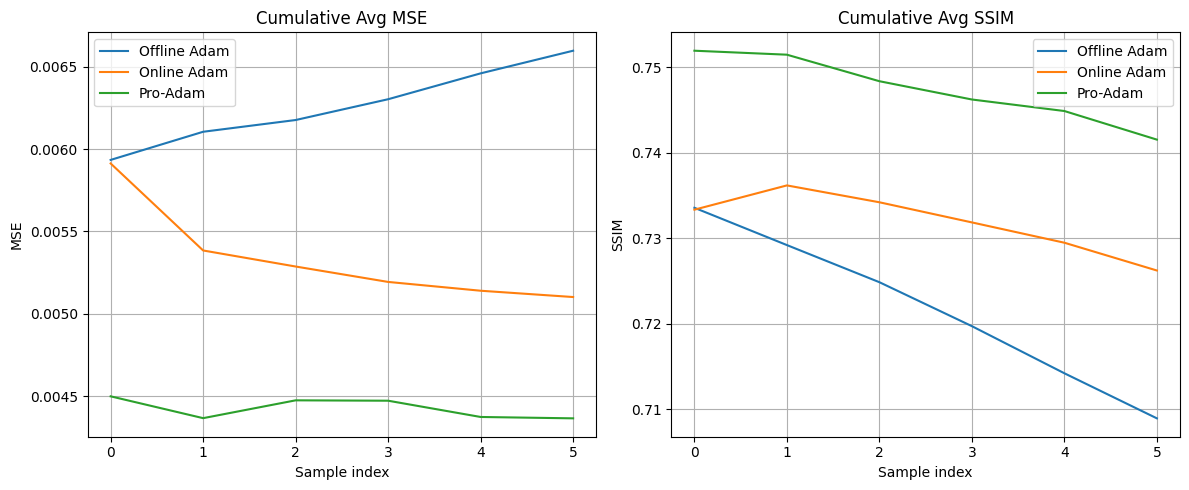

In [ ]:
visualize_cumulative_comparison({"Offline Adam": h_off_org,
                                 "Online Adam": h_std_adam,
                                 "Pro-Adam": h_pro_std})

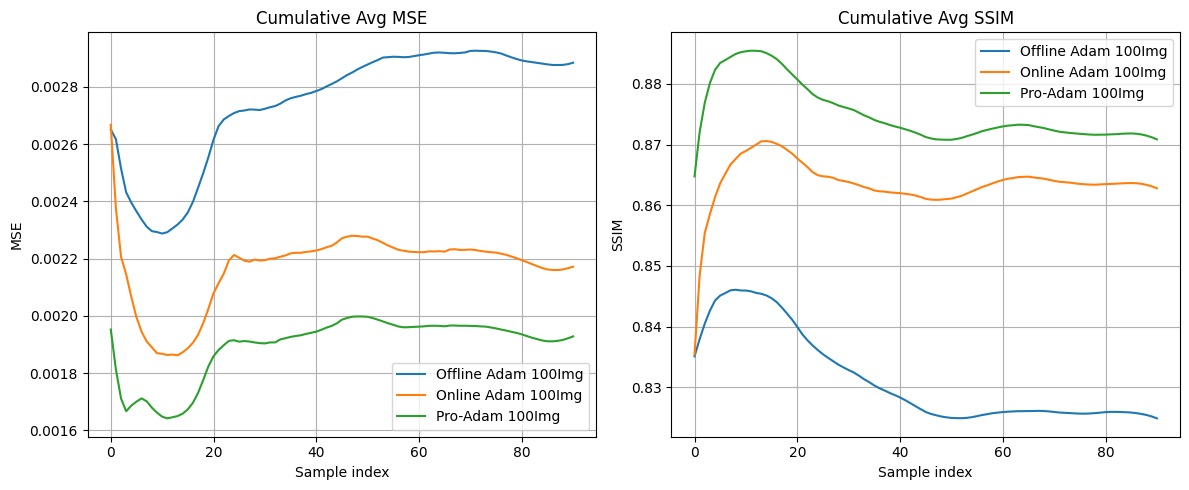

In [ ]:
visualize_cumulative_comparison({"Offline Adam 100Img": h_off_org_100,
                                 "Online Adam 100Img": h_std_adam_100,
                                 "Pro-Adam 100Img": h_pro_std_100})

### Show kết quả chi tiết

In [ ]:
# ================= UNIVERSAL REPORT SYSTEM ====================================
import numpy as np

SCALE_VAR = 1e5

# ------------------------------------------------------------------------------
def _fmt(x, n=5):
    return f"{x:.{n}f}"

def _fmt_mean_var(arr, scale=SCALE_VAR):
    mean = float(np.mean(arr))
    var = float(np.var(arr))
    return f"{mean:.5f}±{var*scale:.4f}"

# ------------------------------------------------------------------------------
def print_detailed_metric_tables(histories, metric_idx, metric_name):
    """
    histories: dict {"ModelName": history_array}
    history_array shape: (N_samples, steps, 4)
    metric_idx: 0=MSE,1=MAE,2=RMSE,3=SSIM
    """

    print(f"\nBẢNG: ĐÁNH GIÁ TRÊN CHỈ SỐ {metric_name.upper()}\n")

    # Determine steps dynamically
    any_history = next(iter(histories.values()))
    steps = any_history.shape[1]
    cols = [f"t+{i}" for i in range(1, steps+1)]

    header = "Model\tN\t" + "\t".join(cols) + "\tAvg"
    print(header)

    for model_name, H in histories.items():

        for i in range(H.shape[0]):
            row_vals = H[i, :, metric_idx]
            avg = np.mean(row_vals)
            row_str = "\t".join([_fmt(v) for v in row_vals])
            print(f"{model_name}\t{i}\t{row_str}\t{_fmt(avg)}")

        # summary row
        col_mean = np.mean(H[:, :, metric_idx], axis=0)
        col_var = np.var(H[:, :, metric_idx], axis=0)

        summary_cols = [
            f"{col_mean[j]:.5f}±{col_var[j]*SCALE_VAR:.4f}"
            for j in range(len(col_mean))
        ]

        all_vals = H[:, :, metric_idx].flatten()
        summary_avg = _fmt_mean_var(all_vals)

        print(f"\t\t" + "\t".join(summary_cols) + "\t" + summary_avg)


# ------------------------------------------------------------------------------
def print_combined_summary_table(histories):
    """
    Final summary table:
    Model | Frame | MSE±var | MAE±var | RMSE±var | SSIM±var
    Works for 1 or many models.
    """

    metrics = ['MSE', 'MAE', 'RMSE', 'SSIM']

    print("\nTable: Tổng hợp đánh giá trên tập test")
    print("Model\tFrame\tMSE±Var\tMAE±Var\tRMSE±Var\tSSIM±Var")

    for model_name, H in histories.items():

        steps = H.shape[1]

        for t in range(steps):
            line = f"{model_name}\tt+{t+1}"
            for m_idx in range(4):
                arr = H[:, t, m_idx]
                line += "\t" + _fmt_mean_var(arr)
            print(line)

        # ALL STEPS
        line = f"{model_name}\tALL"
        for m_idx in range(4):
            arr_all = H[:, :, m_idx].flatten()
            line += "\t" + _fmt_mean_var(arr_all)
        print(line)


# ------------------------------------------------------------------------------
def print_full_report(histories):
    """
    Master function.
    histories must be dict {"ModelName": history_array}
    """

    if not isinstance(histories, dict):
        raise ValueError("histories must be a dictionary: {'ModelName': history_array}")

    # Validate shapes
    for name, H in histories.items():
        if len(H.shape) != 3 or H.shape[2] != 4:
            raise ValueError(f"{name} history must have shape (N_samples, steps, 4)")

    print("\n================ FULL EVALUATION REPORT ================")

    # Detailed MSE
    print_detailed_metric_tables(histories, metric_idx=0, metric_name="MSE")

    # Detailed SSIM
    print_detailed_metric_tables(histories, metric_idx=3, metric_name="SSIM")

    # Combined table
    print_combined_summary_table(histories)

    print("\n========================================================")


In [ ]:
histories = {"Offline Adam": h_off_org,
            "Online Adam": h_std_adam,
            "Pro-Adam": h_pro_std}

print_full_report(histories)


================ FULL EVALUATION REPORT ================

BẢNG: ĐÁNH GIÁ TRÊN CHỈ SỐ MSE

Model	N	t+1	t+2	t+3	t+4	t+5	t+6	Avg
Offline Adam	0	0.00255	0.00480	0.00573	0.00611	0.00794	0.00848	0.00593
Offline Adam	1	0.00298	0.00452	0.00533	0.00719	0.00790	0.00974	0.00628
Offline Adam	2	0.00254	0.00392	0.00607	0.00706	0.00893	0.00940	0.00632
Offline Adam	3	0.00245	0.00486	0.00626	0.00830	0.00890	0.00933	0.00668
Offline Adam	4	0.00311	0.00520	0.00753	0.00837	0.00897	0.00935	0.00709
Offline Adam	5	0.00301	0.00573	0.00720	0.00816	0.00868	0.01094	0.00729
		0.00277±0.0070	0.00484±0.0311	0.00635±0.0605	0.00753±0.0675	0.00855±0.0209	0.00954±0.0538	0.00660±0.5594
Online Adam	0	0.00255	0.00478	0.00570	0.00609	0.00791	0.00845	0.00591
Online Adam	1	0.00234	0.00334	0.00428	0.00555	0.00627	0.00735	0.00486
Online Adam	2	0.00219	0.00333	0.00474	0.00572	0.00702	0.00754	0.00509
Online Adam	3	0.00217	0.00354	0.00453	0.00582	0.00639	0.00702	0.00491
Online Adam	4	0.00236	0.00355	0.00501	0.00562	0.00625	0.0067

In [ ]:
histories_100 = {"Offline Adam 100Img": h_off_org_100,
                "Online Adam 100Img": h_std_adam_100,
                "Pro-Adam 100Img": h_pro_std_100}

print_full_report(histories_100)


================ FULL EVALUATION REPORT ================

BẢNG: ĐÁNH GIÁ TRÊN CHỈ SỐ MSE

Model	N	t+1	t+2	t+3	t+4	t+5	t+6	Avg
Offline Adam 100Img	0	0.00093	0.00157	0.00233	0.00312	0.00365	0.00430	0.00265
Offline Adam 100Img	1	0.00088	0.00159	0.00239	0.00293	0.00353	0.00418	0.00258
Offline Adam 100Img	2	0.00082	0.00160	0.00202	0.00257	0.00315	0.00371	0.00231
Offline Adam 100Img	3	0.00090	0.00132	0.00187	0.00241	0.00292	0.00367	0.00218
Offline Adam 100Img	4	0.00071	0.00132	0.00192	0.00249	0.00321	0.00386	0.00225
Offline Adam 100Img	5	0.00076	0.00134	0.00188	0.00254	0.00310	0.00366	0.00221
Offline Adam 100Img	6	0.00080	0.00131	0.00194	0.00248	0.00296	0.00350	0.00217
Offline Adam 100Img	7	0.00068	0.00131	0.00189	0.00239	0.00289	0.00367	0.00214
Offline Adam 100Img	8	0.00075	0.00136	0.00191	0.00239	0.00315	0.00346	0.00217
Offline Adam 100Img	9	0.00082	0.00144	0.00195	0.00269	0.00302	0.00367	0.00227
Offline Adam 100Img	10	0.00086	0.00136	0.00211	0.00242	0.00302	0.00363	0.00223
Offline Adam 1